<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI" width="280"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup guide](README.md)

# 01 · The same lead time, different delivery dates

**What does “two business days” mean when teams follow different holiday calendars?**
A weekday recurrence can still land on a public holiday. We will generate a small
synthetic dispatch schedule, check three regional calendars, roll closed dispatch
days forward, and compare business-day delivery dates with simple date addition.

The requests are **synthetic**. Holiday rules come from the pinned `holidays==0.108`
library through the real VGI worker; they are not carrier service
commitments. We assume Saturday/Sunday weekends, no cutoff hour and one regional
calendar governing both dispatch and delivery. The analysis runs locally.

## Choose the service lead time

`LEAD_BUSINESS_DAYS` accepts integers **1–7**. The default is **2**; the final
experiment changes it to **5**. Edit the cell, then **Restart Kernel → Run All**.

Nine requested dispatches are generated from **21–31 December 2026**, inclusive.
The chart calendar covers **21 December 2026–15 January 2027**, inclusive, so it
also covers the longest permitted lead time. These are civil dates, not elapsed
24-hour periods. The recurrence uses naive local midnight timestamps before
conversion to DATE; it does not represent simultaneous UTC departures.

In [1]:
LEAD_BUSINESS_DAYS = 2

In [2]:
import os
import sys
from pathlib import Path

os.environ["PLOOMBER_STATS_ENABLED"] = "false"
NOTEBOOK_DIR = Path.cwd() if (Path.cwd() / "notebook_support.py").is_file() else Path.cwd() / "notebooks"
sys.path.insert(0, str(NOTEBOOK_DIR))

In [3]:
import haybarn
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from notebook_support import COLORS, finish, prose, theme

if isinstance(LEAD_BUSINESS_DAYS, bool) or not isinstance(LEAD_BUSINESS_DAYS, int) or not 1 <= LEAD_BUSINESS_DAYS <= 7:
    raise ValueError("LEAD_BUSINESS_DAYS must be an integer from 1 to 7.")
theme()
con = haybarn.connect(config={"TimeZone": "UTC"})
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%config SqlMagic.displaycon = False
%sql con
%matplotlib inline

Tip: You may define configurations in /Users/rusty/Development/vgi-calendar/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/vgi-calendar/notebooks/pyproject.toml.

## Connect and discover the regional codes

The literal `uvx` command below installs release **v0.5.0** directly from GitHub
and starts its published entry point. It pins the calendar data library to
**holidays 0.108** and SDK to **vgi-python 0.51.0**. No worker checkout or local
worker environment is required. `uv` and Git must be available on PATH; the first
run downloads its Python runtime and dependencies. Subsequent calendar calculations
are local. The separate notebook environment pins published Haybarn **2.0.0rc11**.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'cal' (TYPE vgi, LOCATION 'uvx --python 3.13 --with holidays==0.108 --with vgi-python==0.51.0 --from git+https://github.com/Query-farm/vgi-calendar@v0.5.0 vgi-calendar-worker');
SELECT country, subdivision FROM cal.main.supported_countries
WHERE (country = 'US' AND subdivision = 'NY')
   OR (country = 'GB' AND subdivision = 'ENG')
   OR (country = 'DE' AND subdivision = 'BY')
ORDER BY country;

,country,subdivision
0,DE,BY
1,GB,ENG
2,US,NY


## A weekday recurrence is only a request schedule

The RFC-5545 rule selects Monday through Friday and stops after nine occurrences.
It does not remove public holidays. We materialize it once and use the same request
dates for New York (`US/NY`), England (`GB/ENG`) and Bavaria (`DE/BY`).

In [5]:
%%sql
CREATE OR REPLACE TABLE requests AS
SELECT seq + 1 AS request_id, occurrence::DATE AS requested_date
FROM cal.main.rrule(TIMESTAMP '2026-12-21 00:00:00',
  'FREQ=DAILY;BYDAY=MO,TU,WE,TH,FR;COUNT=9');
SELECT * FROM requests ORDER BY request_id;

,request_id,requested_date
0,1,2026-12-21
1,2,2026-12-22
2,3,2026-12-23
3,4,2026-12-24
4,5,2026-12-25
5,6,2026-12-28
6,7,2026-12-29
7,8,2026-12-30
8,9,2026-12-31


## See which dates are available

Country and subdivision are **constant positional arguments** for these scalar
functions. Separate SQL branches make that requirement visible. Public holidays
can overlap weekends; the chart gives holidays priority and retains both flags in
the table. Holiday labels are supplied by the library in English.

In [6]:
%%sql
CREATE OR REPLACE TABLE calendar AS
SELECT 'New York' AS region, d::DATE AS date,
       cal.main.is_business_day(d::DATE, 'US', 'NY') AS available,
       cal.main.is_holiday(d::DATE, 'US', 'NY') AS holiday,
       cal.main.holiday_name(d::DATE, 'US', 'NY') AS holiday_name,
       isodow(d) IN (6,7) AS weekend
FROM generate_series(DATE '2026-12-21', DATE '2027-01-15', INTERVAL 1 DAY) t(d)
UNION ALL
SELECT 'England' AS region, d::DATE AS date,
       cal.main.is_business_day(d::DATE, 'GB', 'ENG') AS available,
       cal.main.is_holiday(d::DATE, 'GB', 'ENG') AS holiday,
       cal.main.holiday_name(d::DATE, 'GB', 'ENG') AS holiday_name,
       isodow(d) IN (6,7) AS weekend
FROM generate_series(DATE '2026-12-21', DATE '2027-01-15', INTERVAL 1 DAY) t(d)
UNION ALL
SELECT 'Bavaria' AS region, d::DATE AS date,
       cal.main.is_business_day(d::DATE, 'DE', 'BY') AS available,
       cal.main.is_holiday(d::DATE, 'DE', 'BY') AS holiday,
       cal.main.holiday_name(d::DATE, 'DE', 'BY') AS holiday_name,
       isodow(d) IN (6,7) AS weekend
FROM generate_series(DATE '2026-12-21', DATE '2027-01-15', INTERVAL 1 DAY) t(d);
SELECT region, date, holiday_name, weekend FROM calendar WHERE holiday ORDER BY date, region;

,region,date,holiday_name,weekend
0,Bavaria,2026-12-25,Christmas Day,False
1,England,2026-12-25,Christmas Day,False
2,New York,2026-12-25,Christmas Day,False
3,Bavaria,2026-12-26,Second Day of Christmas,True
4,England,2026-12-26,Boxing Day,True
5,England,2026-12-28,Boxing Day (observed),False
6,Bavaria,2027-01-01,New Year's Day,False
7,England,2027-01-01,New Year's Day,False
8,New York,2027-01-01,New Year's Day,False
9,Bavaria,2027-01-06,Epiphany,False


In [7]:
%%sql calendar_frame <<
SELECT *, CASE WHEN holiday THEN 2 WHEN weekend THEN 1 ELSE 0 END AS day_kind FROM calendar ORDER BY region, date;

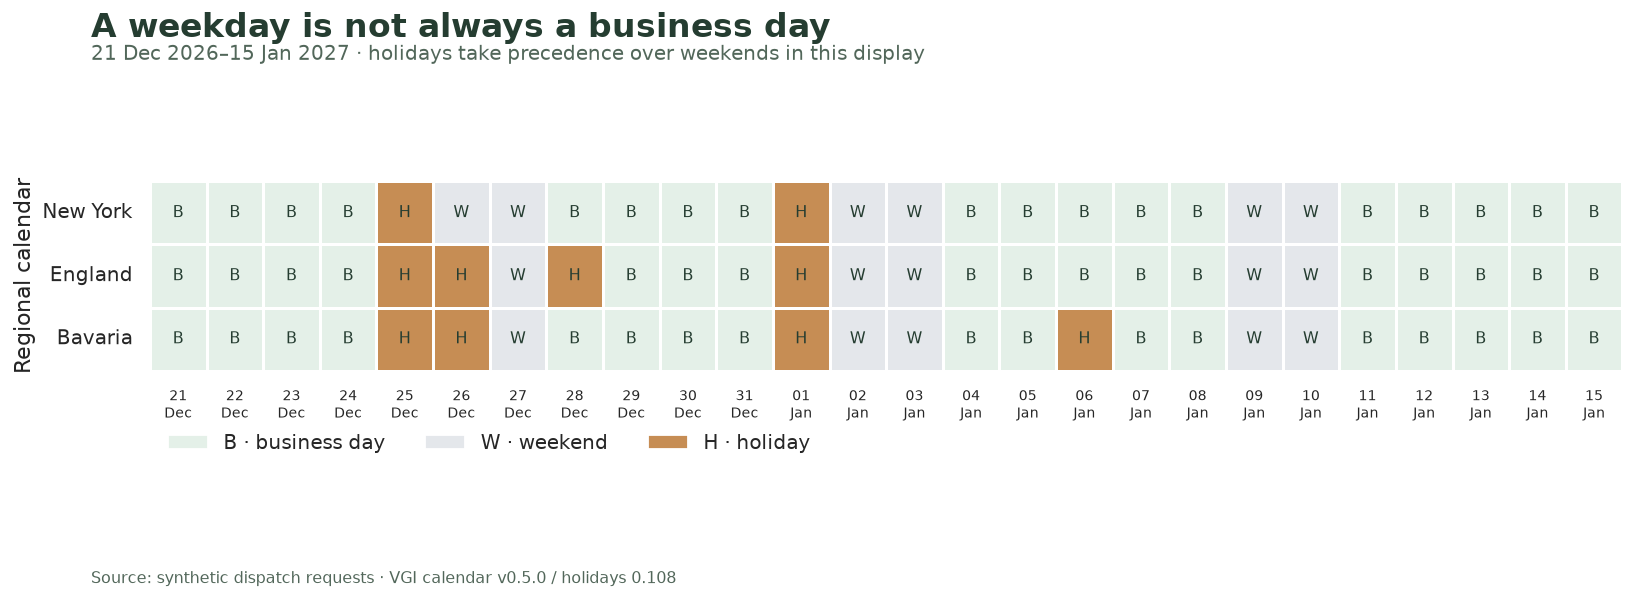

In [8]:
calendar_frame = globals()["calendar_frame"]
grid = calendar_frame.pivot(index="region", columns="date", values="day_kind").reindex(list(COLORS))
fig, ax = plt.subplots(figsize=(13, 4.6))
sns.heatmap(
    grid,
    ax=ax,
    cmap=ListedColormap(["#e4f0e8", "#e4e7eb", "#c68d54"]),
    vmin=0,
    vmax=2,
    linewidths=1.5,
    linecolor="white",
    cbar=False,
    annot=False,
)
for y in range(len(grid)):
    for x in range(len(grid.columns)):
        ax.text(
            x + 0.5,
            y + 0.5,
            ["B", "W", "H"][int(grid.iloc[y, x])],
            ha="center",
            va="center",
            fontsize=9,
            color="#253d31",
        )
ax.set_xticklabels([pd.Timestamp(d).strftime("%d\n%b") for d in grid.columns], rotation=0, fontsize=8)
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set(xlabel="", ylabel="Regional calendar")
ax.legend(
    handles=[
        Patch(facecolor=c, label=label)
        for c, label in [("#e4f0e8", "B · business day"), ("#e4e7eb", "W · weekend"), ("#c68d54", "H · holiday")]
    ],
    loc="upper left",
    bbox_to_anchor=(0, -0.24),
    ncol=3,
    frameon=False,
)
finish(
    fig,
    "A weekday is not always a business day",
    "21 Dec 2026–15 Jan 2027 · holidays take precedence over weekends in this display",
    "01_regional_calendars.png",
)

## Roll dispatches forward, then count the service days

Our explicit policy moves a closed requested dispatch date to the **next** business
day. It then counts `LEAD_BUSINESS_DAYS` strictly **after dispatch**, skipping
weekends and holidays. The worker's `add_business_days(date, 0)` leaves a date
unchanged, so it would not perform the first adjustment.

The naive comparison simply adds the same integer to the requested date. Both
calculations are civil-date models; neither includes hours, cross-border transit
or a destination calendar separate from the dispatch calendar.

In [9]:
%%sql
CREATE OR REPLACE TABLE deliveries AS
SELECT 'New York' AS region, *,
       cal.main.add_business_days(dispatch_date, {{ LEAD_BUSINESS_DAYS }}, 'US', 'NY') AS delivery_date
FROM (SELECT *, CASE WHEN cal.main.is_business_day(requested_date, 'US', 'NY')
    THEN requested_date ELSE cal.main.add_business_days(requested_date, 1, 'US', 'NY') END AS dispatch_date
    FROM requests)
UNION ALL
SELECT 'England' AS region, *,
       cal.main.add_business_days(dispatch_date, {{ LEAD_BUSINESS_DAYS }}, 'GB', 'ENG') AS delivery_date
FROM (SELECT *, CASE WHEN cal.main.is_business_day(requested_date, 'GB', 'ENG')
    THEN requested_date ELSE cal.main.add_business_days(requested_date, 1, 'GB', 'ENG') END AS dispatch_date
    FROM requests)
UNION ALL
SELECT 'Bavaria' AS region, *,
       cal.main.add_business_days(dispatch_date, {{ LEAD_BUSINESS_DAYS }}, 'DE', 'BY') AS delivery_date
FROM (SELECT *, CASE WHEN cal.main.is_business_day(requested_date, 'DE', 'BY')
    THEN requested_date ELSE cal.main.add_business_days(requested_date, 1, 'DE', 'BY') END AS dispatch_date
    FROM requests);
CREATE OR REPLACE TABLE comparison AS
SELECT *, requested_date + {{ LEAD_BUSINESS_DAYS }} AS naive_date,
       dispatch_date - requested_date AS dispatch_wait_days,
       delivery_date - requested_date AS elapsed_calendar_days,
       delivery_date - (requested_date + {{ LEAD_BUSINESS_DAYS }}) AS extra_calendar_days
FROM deliveries;
SELECT * FROM comparison ORDER BY requested_date, region;

,region,request_id,requested_date,dispatch_date,delivery_date,naive_date,dispatch_wait_days,elapsed_calendar_days,extra_calendar_days
0,Bavaria,1,2026-12-21,2026-12-21,2026-12-23,2026-12-23,0,2,0
1,England,1,2026-12-21,2026-12-21,2026-12-23,2026-12-23,0,2,0
2,New York,1,2026-12-21,2026-12-21,2026-12-23,2026-12-23,0,2,0
3,Bavaria,2,2026-12-22,2026-12-22,2026-12-24,2026-12-24,0,2,0
4,England,2,2026-12-22,2026-12-22,2026-12-24,2026-12-24,0,2,0
5,New York,2,2026-12-22,2026-12-22,2026-12-24,2026-12-24,0,2,0
6,Bavaria,3,2026-12-23,2026-12-23,2026-12-28,2026-12-25,0,5,3
7,England,3,2026-12-23,2026-12-23,2026-12-29,2026-12-25,0,6,4
8,New York,3,2026-12-23,2026-12-23,2026-12-28,2026-12-25,0,5,3
9,Bavaria,4,2026-12-24,2026-12-24,2026-12-29,2026-12-26,0,5,3


In [10]:
%%sql summary <<
SELECT region, COUNT(*) AS requests,
COUNT(*) FILTER (WHERE dispatch_wait_days > 0) AS shifted_dispatches,
MIN(elapsed_calendar_days) AS minimum_elapsed_days, MAX(elapsed_calendar_days) AS maximum_elapsed_days,
MAX(extra_calendar_days) AS maximum_extra_days
FROM comparison GROUP BY region ORDER BY region;

In [11]:
summary = globals()["summary"]
display(summary)
parts = [
    f"{r.region}: {r.minimum_elapsed_days}–{r.maximum_elapsed_days} calendar days, "
    f"dispatches shifted: {r.shifted_dispatches}"
    for r in summary.itertuples()
]
prose(
    f"At **{LEAD_BUSINESS_DAYS} business days**, the same request schedule produces: **"
    + "; ".join(parts)
    + "**. The differences reflect the chosen calendars and dispatch policy, not observed shipping performance."
)

,region,requests,shifted_dispatches,minimum_elapsed_days,maximum_elapsed_days,maximum_extra_days
0,Bavaria,9,1,2,5,3
1,England,9,2,2,6,4
2,New York,9,1,2,5,3


At **2 business days**, the same request schedule produces: **Bavaria: 2–5 calendar days, dispatches shifted: 1; England: 2–6 calendar days, dispatches shifted: 2; New York: 2–5 calendar days, dispatches shifted: 1**. The differences reflect the chosen calendars and dispatch policy, not observed shipping performance.

In [12]:
%%sql delivery_frame <<
SELECT * FROM comparison ORDER BY region, requested_date;

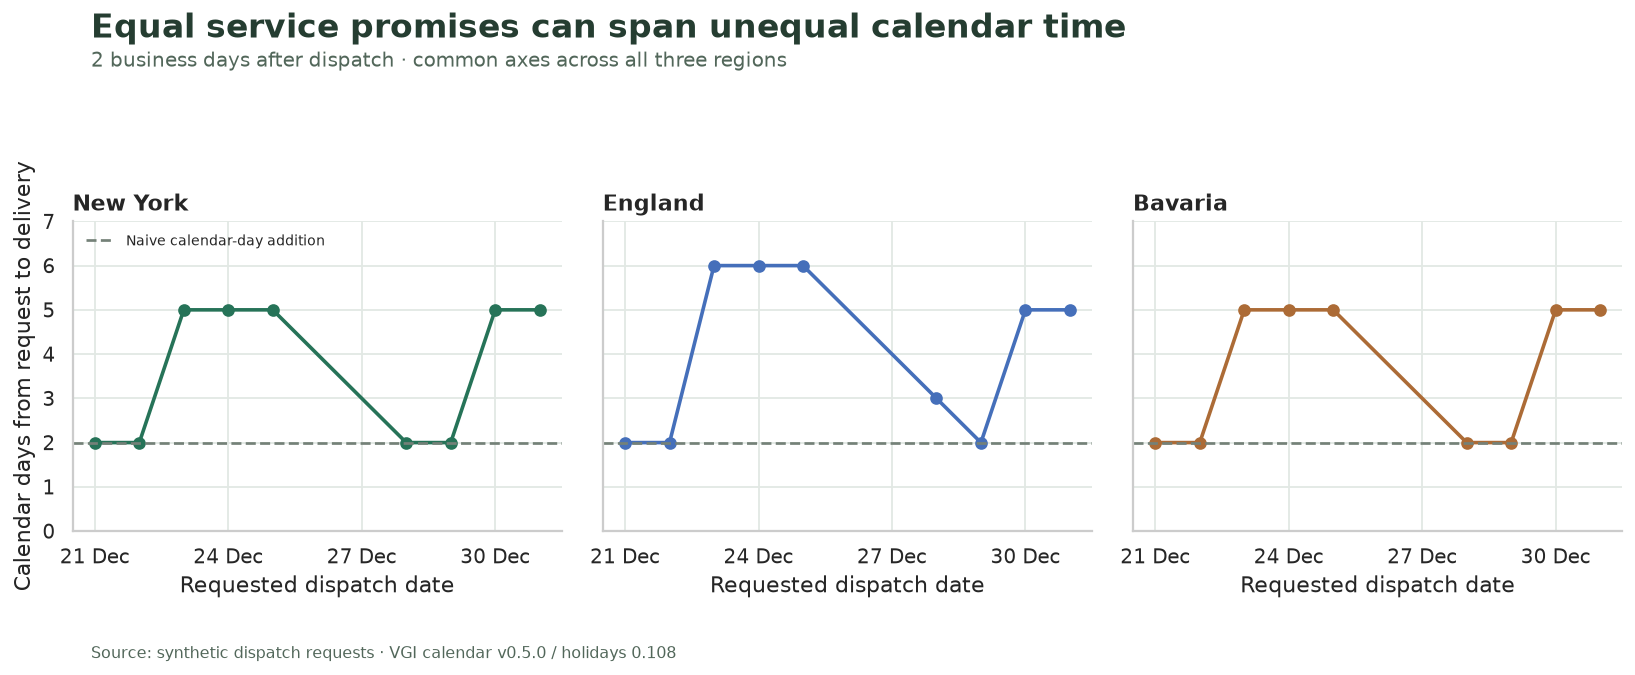

In [13]:
delivery_frame = globals()["delivery_frame"]
fig, axes = plt.subplots(1, 3, figsize=(13, 5.2), sharex=True, sharey=True)
for ax, (region, color) in zip(axes, COLORS.items(), strict=True):
    rows = delivery_frame[delivery_frame.region == region]
    ax.plot(pd.to_datetime(rows.requested_date), rows.elapsed_calendar_days, marker="o", color=color, linewidth=2)
    ax.axhline(LEAD_BUSINESS_DAYS, linestyle="--", color="#748178", label="Naive calendar-day addition")
    ax.set_title(region, loc="left", weight="bold")
    ax.set_xlabel("Requested dispatch date")
    ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
    ax.set_ylim(0, max(delivery_frame.elapsed_calendar_days) + 1)
axes[0].set_ylabel("Calendar days from request to delivery")
axes[0].legend(loc="upper left", fontsize=8, frameon=False)
finish(
    fig,
    "Equal service promises can span unequal calendar time",
    f"{LEAD_BUSINESS_DAYS} business days after dispatch · common axes across all three regions",
    "02_elapsed_days.png",
)

## Follow one request across the year boundary

The final request falls on 31 December. Place the requested date, adjusted dispatch
and delivery on one civil-date axis. A marker shared by request and dispatch means
no dispatch adjustment was required. The cross marker is simple calendar addition.

/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/ipykernel_61216/3228891692.py:21: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(last.requested_date.min()) - pd.Timedelta(days=1),
/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/ipykernel_61216/3228891692.py:22: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.Timestamp(last.delivery_date.max()) + pd.Timedelta(days=2),


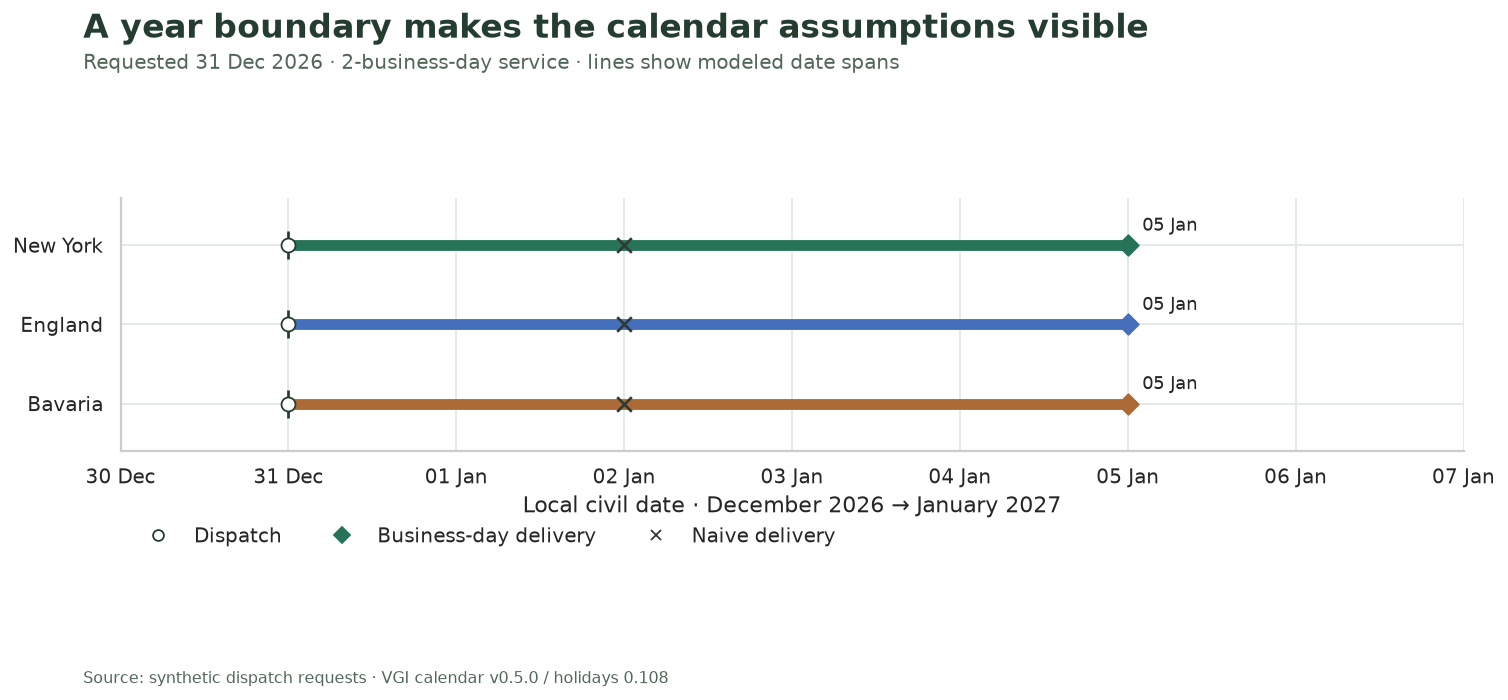

For the final request: **New York: 05 Jan 2027**; **England: 05 Jan 2027**; **Bavaria: 05 Jan 2027**. Consult the holiday table to explain any difference; the calendar uses the pinned library rules.

In [14]:
last = (
    delivery_frame[delivery_frame.requested_date == delivery_frame.requested_date.max()]
    .set_index("region")
    .loc[list(COLORS)]
)
fig, ax = plt.subplots(figsize=(12, 5.4))
for y, (region, row) in enumerate(last.iterrows()):
    start, end = pd.Timestamp(row.requested_date), pd.Timestamp(row.delivery_date)
    ax.plot([start, end], [y, y], color=COLORS[region], linewidth=6, solid_capstyle="round")
    ax.scatter([start], [y], marker="|", s=240, color="#253d31", zorder=4)
    ax.scatter([pd.Timestamp(row.dispatch_date)], [y], marker="o", s=60, color="white", edgecolor="#253d31", zorder=5)
    ax.scatter([end], [y], marker="D", s=65, color=COLORS[region], zorder=5)
    ax.scatter([pd.Timestamp(row.naive_date)], [y], marker="x", s=65, color="#303b35", zorder=6)
    ax.annotate(end.strftime("%d %b"), (end, y), xytext=(8, 8), textcoords="offset points", fontsize=10)
ax.set_yticks(range(3), list(COLORS))
ax.invert_yaxis()
ax.set_ylim(2.6, -0.6)
ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
ax.set_xlim(
    pd.Timestamp(last.requested_date.min()) - pd.Timedelta(days=1),
    pd.Timestamp(last.delivery_date.max()) + pd.Timedelta(days=2),
)
ax.set_xlabel("Local civil date · December 2026 → January 2027")
ax.plot([], [], marker="o", markerfacecolor="white", color="#253d31", linestyle="", label="Dispatch")
ax.plot([], [], marker="D", color="#267358", linestyle="", label="Business-day delivery")
ax.plot([], [], marker="x", color="#303b35", linestyle="", label="Naive delivery")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.23), ncol=3, frameon=False)
finish(
    fig,
    "A year boundary makes the calendar assumptions visible",
    f"Requested 31 Dec 2026 · {LEAD_BUSINESS_DAYS}-business-day service · lines show modeled date spans",
    "03_year_boundary.png",
)
prose(
    "For the final request: "
    + "; ".join(f"**{r}: {pd.Timestamp(row.delivery_date):%d %b %Y}**" for r, row in last.iterrows())
    + ". Consult the holiday table to explain any difference; the calendar uses the pinned library rules."
)

## Check the endpoint convention

`business_days_between(start, end)` uses **[start, end)**, whereas
`business_days(start, end)` returns dates in **[start, end]**. To count the service
days strictly after dispatch and including delivery, use
`business_days_between(dispatch + 1, delivery + 1)`. The SQL compares this count
with the selected lead time and checks that dispatch and delivery are available.

In [15]:
%%sql checks <<
WITH checks AS (SELECT region, request_id,
cal.main.business_days_between(dispatch_date + 1, delivery_date + 1, 'US', 'NY') AS counted_service_days,
cal.main.is_business_day(dispatch_date, 'US', 'NY') AS dispatch_available,
cal.main.is_business_day(delivery_date, 'US', 'NY') AS delivery_available
FROM deliveries WHERE region = 'New York'
UNION ALL
SELECT region, request_id,
cal.main.business_days_between(dispatch_date + 1, delivery_date + 1, 'GB', 'ENG') AS counted_service_days,
cal.main.is_business_day(dispatch_date, 'GB', 'ENG') AS dispatch_available,
cal.main.is_business_day(delivery_date, 'GB', 'ENG') AS delivery_available
FROM deliveries WHERE region = 'England'
UNION ALL
SELECT region, request_id,
cal.main.business_days_between(dispatch_date + 1, delivery_date + 1, 'DE', 'BY') AS counted_service_days,
cal.main.is_business_day(dispatch_date, 'DE', 'BY') AS dispatch_available,
cal.main.is_business_day(delivery_date, 'DE', 'BY') AS delivery_available
FROM deliveries WHERE region = 'Bavaria')
SELECT COUNT(*) AS checked_requests,
BOOL_AND(counted_service_days = {{ LEAD_BUSINESS_DAYS }}) AS lead_time_agrees,
BOOL_AND(dispatch_available AND delivery_available) AS endpoints_available,
(SELECT COUNT(*) = COUNT(DISTINCT (region,request_id)) FROM deliveries) AS unique_requests,
(SELECT BOOL_AND(delivery_date BETWEEN DATE '2026-12-21' AND DATE '2027-01-15') FROM deliveries) AS calendar_covers_deliveries
FROM checks;

In [16]:
checks = globals()["checks"]
display(checks)
assert bool(checks.iloc[0, 1:].all()), "Calendar relationship checks failed."
assert int(checks.checked_requests.iloc[0]) == len(delivery_frame)
prose(
    f"**All checks passed for {int(checks.checked_requests.iloc[0])} regional request rows.**"
    "\nService counts, endpoint availability and calendar coverage agree."
)

,checked_requests,lead_time_agrees,endpoints_available,unique_requests,calendar_covers_deliveries
0,27,True,True,True,True


**All checks passed for 27 regional request rows.**
Service counts, endpoint availability and calendar coverage agree.

## Experiment · change two business days to five

Change only **`LEAD_BUSINESS_DAYS = 5`**, then restart and run all. Predict which
parts stay fixed: requested dates, holiday flags and adjusted dispatch dates.
Delivery dates can only move later under this policy, but the extra calendar days
need not rise equally in every region.

Compare the regional elapsed-time panels and the **31 December** request timeline.
Use the holiday table to explain any new separation. The experiment changes the
service rule, not the underlying holiday data or actual transit performance.
Restore **`LEAD_BUSINESS_DAYS = 2`** for the saved example. The [guide](README.md)
shows how to save the five-day run in a separate copy.

In [17]:
con.close()

---

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="210"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Setup and model assumptions](README.md)